## Generating new labels for unseen data to increase training set size

This notebook takes the ensemble of three models and runs it on unseen data to generate labels, the labels with very high (>0.80) and very low (<0.20) are kept as positives and negatives for the next round of training while the inbetweens wil be saved  to be checked manually by yours truly. Yeaah. 

In [41]:
from opensoundscape.annotations import BoxedAnnotations
import numpy as np
import pandas as pd
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt

import opensoundscape as opso
import bioacoustics_model_zoo as bmz
import joblib

Load the model files, check cuda again always check cuda. 

In [42]:
sequence=0
sequence_path = f"annotation_step{sequence}"
# create next sequence path
next_seq_path = f"annotation_step{sequence+1}"
Path(next_seq_path).mkdir(exist_ok=True)
resnet = opso.load_model(Path(sequence_path).joinpath("resnet/best.model"))
effnet = opso.load_model(Path(sequence_path).joinpath("effnet/best.model"))
perch = bmz.Perch2ONNX(headless=True)
shallow = joblib.load(Path(sequence_path).joinpath("shallow_perch/shallow_classifier.joblib"))
import torch
torch.cuda.is_available()

/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/preprocess/overlay.py:126: UserWarning: Overlay class's .overlay_df will be None after loading from dict and `.criterion_fn` will be always_true(). Reset these attributes and set .bypass to False to use Overlay after loading with from_dict().
  warnings.warn(
/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/preprocess/overlay.py:126: UserWarning: Overlay class's .overlay_df will be None after loading from dict and `.criterion_fn` will be always_true(). Reset these attributes and set .bypass to False to use Overlay after loading with from_dict().
  warnings.warn(


True

Load the files to check. They will be a combination of the rest of the first airgun folder and some of the "background files"

TODO: the sampling by percentage is gonna give me problems when the number of files is very small maybe i can put a rule that allos me to slect the smallest of 25 or the percentage

In [ ]:
from Keys import airgun_folder, background_folder
airgun_folder=Path(airgun_folder)
background_folder=Path(background_folder)
# the files used during training or validation should not be included they can be found here
files_training = pd.read_csv(Path(sequence_path).joinpath("Already_trained_on_files.csv"))

#glob the files for airguns
airgun_files = glob(str(airgun_folder.joinpath('*.wav')))
# erase the first two files that are the joined ones
airgun_files=airgun_files[2:]
# select the one that the model has not been trained on it should be 322
airgun_files = [x for x in  airgun_files if  Path(x).name not in set(files_training.loc[files_training['folder']=="Airgun",'file']) ]


# glob the files for the background
background_files=glob(str(background_folder.joinpath("*.wav")))
background_files=[x for x in  background_files if  Path(x).name not in set(files_training.loc[files_training['folder']=="background",'file']) ]

# subsample 10% of the background noises and 25% of the airguns so i dont use all of them 
import random
import math
random.seed(3101992)
ag_to_select= max(25,math.floor(len(airgun_files)*0.25))
bg_to_select =max(25, math.floor(len(background_files)*0.1))
airgun_files_s = random.sample(airgun_files, ag_to_select)
background_files_s =random.sample(background_files,bg_to_select )

# add the selected files to the already trained files csv
This_seq_train = pd.DataFrame({
    "file":   [Path(x).name for x in airgun_files_s] + [Path(x).name for x in background_files_s],
    "folder": ["Airgun"] * len(airgun_files_s) + ["background"] * len(background_files_s),
})

files_training_c = pd.concat([files_training, This_seq_train], ignore_index=True)
files_training_c.to_csv(Path(next_seq_path).joinpath(f"Already_trained_on_files_s{sequence+1}.csv"), index=False)

extract perch emdeddings  for both files, for the embedding we need to create a clips object so the embedding come out related to a file

In [56]:
clips_ag = opso.utils.make_clip_df(airgun_files_s+background_files_s, clip_duration=5)
perch_emb_ag=np.asanyarray(perch.embed(clips_ag, return_dfs=False, return_preds=False))

  0%|          | 0/344 [00:00<?, ?it/s]

load the shallow classifier and run the inference. 

In [58]:
pred_perch=shallow.predict_proba(perch_emb_ag)[:,1]


Plot the results, we have a nice bimodal distribution but the inbetween section is very large. Hopefully it reduces with each iteration. 

(array([125.,  47.,  49.,  37.,  21.,  11.,  14.,   4.,   8.,  28.]),
 array([0.03618746, 0.13210671, 0.22802596, 0.32394521, 0.41986447,
        0.51578372, 0.61170297, 0.70762222, 0.80354147, 0.89946073,
        0.99537998]),
 <BarContainer object of 10 artists>)

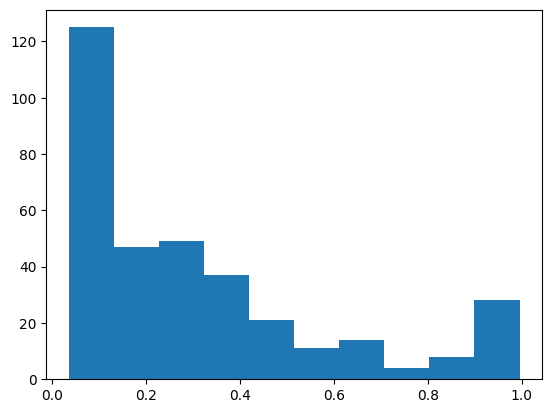

In [59]:
plt.hist(pred_perch)

Create the prediction for the other two models, the argument sigmoid creates true probabilities and the batch needs to be bigger than the default (1) to actually use the gpu. 

In [60]:
pred_resnet = resnet.predict(airgun_files_s + background_files_s, activation_layer="sigmoid",batch_size=32)
pred_effnet = effnet.predict(airgun_files_s + background_files_s, activation_layer="sigmoid",batch_size=32)

  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Plot these as well, we have a similar situation as before. 

Text(0.5, 1.0, 'Distribition of scores resnet')

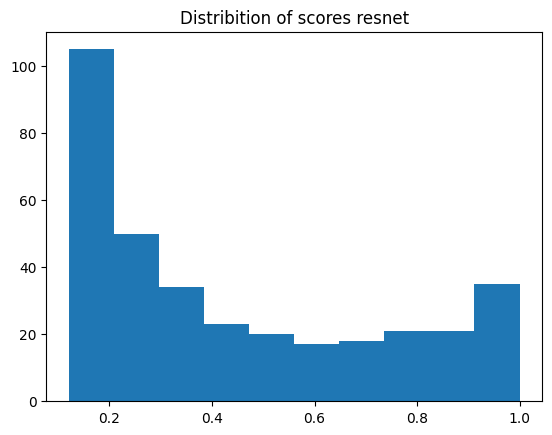

In [61]:
plt.hist(pred_resnet['airgun'])
plt.title("Distribition of scores resnet")

Text(0.5, 1.0, 'Distribition of scores eff_net0')

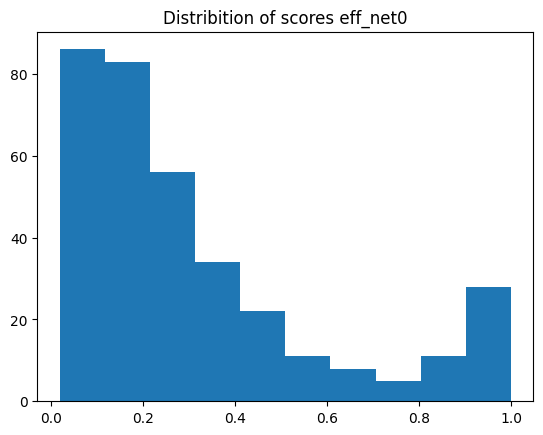

In [62]:
plt.hist(pred_effnet['airgun'])
plt.title("Distribition of scores eff_net0")

Check for the files that are above and below the thresholds for the whole ensamble, here is important to remember that i have twice as many embeddings rows as i have files because most of the files are 10 second and the split was every 5 seconds. 

For the enemble I will use a simple mean of the scores but I will add an additional rule that reject the score if the variation between models was higher than 0.4. 

In [63]:
ens = pd.DataFrame({
    "resnet": pred_resnet["airgun"],
    "effnet": pred_effnet["airgun"],
}, index=clips_ag.index)            
ens["perch"] = pred_perch          
# hacky way to check for nas that i found.  
assert not ens.isna().any().any()  

ens["mean"] = ens[["resnet", "effnet", "perch"]].mean(axis=1)
ens["spread"] = ens[["resnet", "effnet", "perch"]].max(axis=1) - ens[["resnet", "effnet", "perch"]].min(axis=1)

positives = ens[(ens["mean"] > 0.8) & (ens["spread"] < 0.40)]
negatives = ens[(ens["mean"] < 0.2) & (ens["spread"] < 0.4)]
review    = ens.drop(positives.index).drop(negatives.index)




print(len(positives), len(negatives), len(review))


33 115 196


We will check randomly 50% of the positives and the negatives to make sure that they are correct. If  more than five percent of the selected ones are not in the correct category move the threshold. 

In [64]:
from opensoundscape.visualization import annotate, inspect

positives_df = positives.reset_index()
widget= annotate(positives_df, N=math.floor(len(positives)*0.5), 
                 annotation_buttons=['airgun'],bandpass_range=(0,2000),
                 spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

It looks good for the positives, very clear airguns selected. 

In [65]:
n_checked = math.floor(len(positives) * 0.5)
n_wrong = (positives_df["airgun"] == 1).sum()      # clips you marked as airgun after all
print(f"of {n_checked} checked positives, {n_wrong} ({n_wrong / n_checked * 100:.1f}%) were correctly labelled as airgun")

of 16 checked positives, 16 (100.0%) were correctly labelled as airgun


again check 50% of the negatives

In [16]:
negatives_df=negatives.reset_index()
widget= annotate(negatives_df, annotation_buttons=['airgun'], N=math.floor(len(negatives)*0.5), bandpass_range=(0,3000),
                 spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})


GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [66]:
n_checked = math.floor(len(negatives) * 0.5)
n_wrong = (negatives_df["airgun"] == 1).sum()      # clips you marked as airgun after all
print(f"of {n_checked} checked negatives, {n_wrong} ({n_wrong / n_checked * 100:.1f}%) were wrongly labelled as negative")

of 57 checked negatives, 1 (1.8%) were wrongly labelled as negative


The files that need to be reviwed can be annotated here direclty. 

In [67]:
review_df = review.reset_index()
print(f"you will have to review {len(review)} snippets, get ready!")

you will have to review 196 snippets, get ready!


In [72]:

batch = 4                 # increase by 1 for each new batch

idx = review_df.index[batch * 50 : (batch + 1) * 50]
annotate(review_df, indices=list(idx), 
         annotation_buttons=["airgun"], N=20,
         bandpass_range=(0, 1500),
         spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})
review_df.to_csv(Path(next_seq_path).joinpath("review_progress.csv"), index=False)

GridBox(layout=Layout(grid_gap='0px', grid_template_columns='repeat(auto-fill, minmax(250px, 1fr))'))

Print all the added airguns to the dataset

In [73]:
pos_idx = list(review_df.index[review_df["airgun"] == 1])
print(len(pos_idx))          # should be 31

widget = annotate(review_df, indices=pos_idx, N=len(pos_idx),
         bandpass_range=(0, 1500),
         spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

26


GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [74]:
print(f"from  a total of {len(review)} review files {(review_df['airgun'].eq(True)).sum()} are airguns and the rest are nothing (negatives)")

from  a total of 196 review files 26 are airguns and the rest are nothing (negatives)


In [75]:
labels = pred_resnet.copy()                
labels["airgun"] = 0                        

# reviewed airguns by file + times, not by row number
rev_keys = review_df.loc[review_df["airgun"].eq(True), ["file", "start_time", "end_time"]]
labels.loc[pd.MultiIndex.from_frame(rev_keys), "airgun"] = 1

# auto-accepted positives (already indexed by file + times)
pos_keys = positives_df[["file", "start_time", "end_time"]]
labels.loc[pd.MultiIndex.from_frame(pos_keys), "airgun"] = 1

print(labels["airgun"].value_counts())   



airgun
0    285
1     59
Name: count, dtype: int64


Save as a set of raven tables and as csv usable for future training. I dont have a lot of use for the annotations in raven Right now because of Raven lite but maybe they can be useful. 

TODO: finish this part, it needs to save the raven files in the correct folder and then merged the labels of the previous and current, also it needs to load the labels from the previous sequence if it is not the first one. 

In [ ]:
from Keys import annotation_file_tr_og, audio_file_file_tr_og
annot_list = [annotation_file_tr_og]
audio_list = [audio_file_file_tr_og]

if sequence ==1:
    annotations_og = BoxedAnnotations.from_raven_files(
        raven_files=annot_list,
        audio_files=audio_list,
        annotation_column=None)

    # Inspect the object's .df attribute
    # which contains the table of annotations
    annotations_og.df["annotation"] = "airgun"
    annotations_og_df  = annotations_og.df

In [ ]:
from opensoundscape.annotations import BoxedAnnotations
sequence =1 
sequential_annotation_folder=f"annotations_step{sequence}" 
Path(sequential_annotation_folder).mkdir(exist_ok=True)
pos = labels[labels["airgun"] == 1].reset_index()
# labels from this  iteration, 
df = pd.DataFrame({
    "audio_file": pos["file"],
    "start_time": pos["start_time"],
    "end_time":   pos["end_time"],
    "annotation": "airgun",
    "low_f": 0,
    "high_f": 1000,
})
# labels from the previous iteration
all_files = labels.index.get_level_values("file").unique().tolist()

# combine with the annotations from previois step  annotations. 
boxes = BoxedAnnotations(df, audio_files=all_files)


boxes.to_csv(Path(sequential_annotation_folder).joinpath(f"ML_annotations_step{sequence}.csv"))       # OpenSoundscape's own format
boxes.to_raven_files(sequential_annotation_folder,
                     audio_files=boxes.df["audio_file"])         # Raven tables (the folder must exist)